# Lecture 29 notebook: carry and value

This notebook replays Lecture 29. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process. The data are free and kept local, never committed: FRED (exchange rates, OECD rates and yields, CPI, the bill rate), the BIS real exchange rates, the central banks' daily 10-year yields (sources in `results/bond_yield_sources.md`), Shiller's S&P 500 data, Yahoo Finance (country funds and their distributions), the World Bank (PPP, commodity prices), EIA and USDA (inventories), the AQR Data Library (a check only), and the capstone futures of Lecture 11.

By default the notebook shows the shipped figures and results and checks the lecture's mechanics by hand. `RUN_ALL` also reruns every analysis, one script at a time, into a separate folder, and compares the key numbers with the shipped ones. Recomputed results never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings and data | |
| 1 | The key chart | §1 |
| 3 | Our value against AQR's, by hand | §3 |
| 4 | Carry: a currency return and a carry score by hand | §4 |
| 5 | Value: price and fundamentals | §5 |
| 6 | Results: the number of tries and the deflated Sharpe ratio by hand; years needed; regimes | §6 |
| 7 | What did not add; the split by trend's position | §7 |
| 8 | Shipped against recomputed; a construction of your own | |

## 0. Settings and data

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd
from scipy.stats import norm
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l29 as L, l29_combined as MC, l29_bonds_g10 as G, l29_grids as GR
RUN_ALL = False                                                            # True: also rerun every analysis

SHIPPED = HERE / "results"; WORK = L.RAW / "l29_results"                  # recomputed results go to WORK, never over the shipped ones
if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
FUTURES = L.FT.CACHE.exists()
print("shipped results:", SHIPPED, "| recomputed results:", WORK, "| capstone futures found:", FUTURES)


def run(script, *args, show=False):
    "Run a script of this lecture in a fresh process; figures as nb_*, results to WORK."
    t0 = time.time()
    env = {**os.environ, "PORTFOLIO_DATA": str(L.L28.L25.DATA), "L29_RESULTS": str(WORK), "L29_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def result(name, where=None):
    return json.loads(((where or WORK) / name).read_text(encoding="utf-8"))

shipped results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\lectures\29-carry-and-value\results | recomputed results: C:\Users\maxgn\New Trading Models\data\raw\l29_results | capstone futures found: True


## 1. The key chart

Trend (Lecture 27's baseline across all its markets), carry (four groups) and the two at equal risk. `l29_key_chart.py` redraws it.

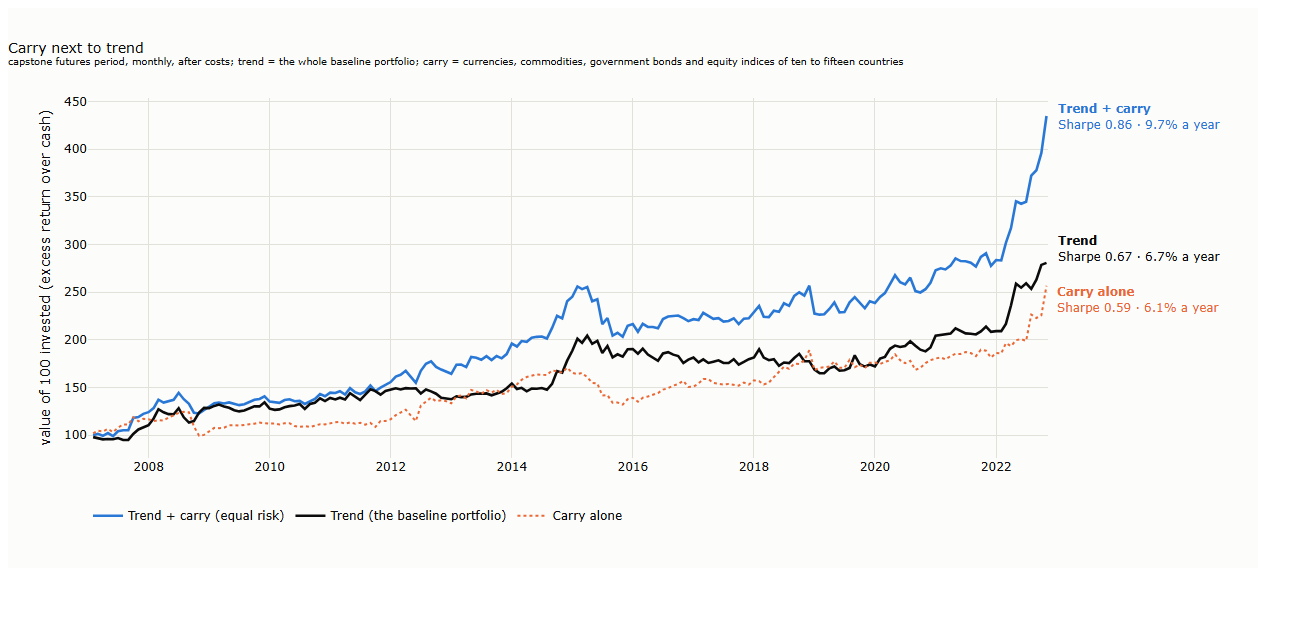

,Trend + carry (equal risk),Trend (the baseline portfolio),Carry alone
sharpe,0.865,0.672,0.586
ret,0.097,0.067,0.061
maxdd,-0.206,-0.193,-0.227
calmar,0.471,0.350,0.271
omega,1.955,1.670,1.643


In [2]:
if RUN_ALL: run("l29_key_chart.py")
f = FIG / ("nb_29_key.png" if RUN_ALL else "29_key.png"); display(Image(filename=str(f)))
K = result("key.json", SHIPPED)
pd.DataFrame({k: {m: round(v[m], 3) for m in ("sharpe", "ret", "maxdd", "calmar", "omega")} for k, v in K.items() if isinstance(v, dict)})

## 3. Our value against AQR's, by hand

The currency group with AQR's construction (the real exchange rate against its average 4.5 to 5.5 years earlier), against AQR's published currency value factor: the correlation of monthly returns, 2006 to October 2022. The lecture reports 0.78.

In [3]:
Gs = MC.groups()
w = G.rank_centred(Gs["fx"]["Va"]); ours = G.stream(w, Gs["fx"]["R"]).loc["2006-01":"2022-10"]
A = G.aqr()["VALLS_VME_FX"]
print("correlation with AQR's currency value:", round(pd.concat([ours, A], axis=1).dropna().corr().iat[0, 1], 2))

correlation with AQR's currency value: 0.79


## 4. Carry by hand

**A currency's return over cash.** The euro in one month: spot change plus the rate gap, against the built series.

In [4]:
S, R, Cg = L.FX.build()
d0, d1 = pd.Timestamp("2015-06-30"), pd.Timestamp("2015-07-31")
spot = S["EUR"].loc[d0:d1]; gap = Cg["EUR"].loc[d0:d1]
by_hand = (spot.iloc[-1] / spot.iloc[0] - 1) + gap.iloc[1:].mean() * (d1 - d0).days / 365
built = (1 + R["EUR"].loc[d0 + pd.Timedelta(days=1):d1]).prod() - 1
print(f"euro, July 2015: by hand {by_hand:+.4%}, built series {built:+.4%} (small gap: daily compounding)")

euro, July 2015: by hand -1.1461%, built series -1.1459% (small gap: daily compounding)


**A carry score.** The currency group in one month: z-scores of the level and the 3-month change, half absolute and half per unit of risk (§4.2), against the script's score.

In [5]:
Cfx, Rfx = Gs["fx"]["C"], Gs["fx"]["R"]; t = pd.Period("2015-06", "M")
vol = (Rfx.rolling(36, min_periods=24).std() * np.sqrt(12)).loc[t]
z = lambda x: (x - x.mean()) / x.std(ddof=0)
lev, chg = Cfx.loc[t], Cfx.loc[t] - Cfx.shift(3).loc[t]
by_hand = ((z(lev) + z(lev / vol)) / 2 + (z(chg) + z(chg / vol)) / 2) / 2
script = GR.sig(Cfx, Rfx).loc[t]
pd.DataFrame({"by hand": by_hand, "script": script, "weight": by_hand / by_hand.abs().sum()}).round(3)

,by hand,script,weight
EUR,-0.342,-0.342,-0.063
JPY,-0.026,-0.026,-0.005
GBP,0.193,0.193,0.036
CHF,-1.049,-1.049,-0.194
CAD,0.722,0.722,0.133
AUD,-0.017,-0.017,-0.003
NZD,0.880,0.880,0.163
NOK,0.910,0.910,0.168
SEK,-1.270,-1.270,-0.235


## 5. Value: price and fundamentals

In [6]:
if RUN_ALL: run("l29_value_fund.py")
V = result("value_fund.json", SHIPPED)
pd.DataFrame({k: {g: round(V[k][g], 2) for g in ("fx", "commod", "bonds", "equity")} | {"all four": round(V[k]["2006-2022"]["value"], 2),
              "trend + value": round(V[k]["2006-2022"]["with_trend"], 2)} for k in ("price (rule)", "fundamental")})

,price (rule),fundamental
fx,-0.14,0.08
commod,-0.12,0.05
bonds,0.28,0.10
equity,0.04,0.17
all four,-0.09,0.14
trend + value,0.47,0.65


## 6. Results

**The number of tries and the deflated Sharpe ratio by hand** (Bailey and López de Prado 2014), from the tries' monthly returns' summary in `results/tries.json`.

In [7]:
if RUN_ALL: run("l29_tries.py")
T = result("tries.json", SHIPPED); r = T["rule"]
sr_all = np.array(list(T["sharpe"].values())) / np.sqrt(12); n = T["n_eff"]; g = 0.5772156649
sr0 = np.sqrt(np.var(sr_all, ddof=1)) * ((1 - g) * norm.ppf(1 - 1 / n) + g * norm.ppf(1 - 1 / (n * np.e)))
zz = (r["sr_month"] - sr0) * np.sqrt(r["T"] - 1) / np.sqrt(1 - r["skew"] * r["sr_month"] + (r["kurt"] - 1) / 4 * r["sr_month"] ** 2)
print(f"tries {T['tries']}, average correlation {T['avg_corr']:.2f}, effective tries {n:.1f}")
print(f"noise benchmark (annual) {sr0 * np.sqrt(12):.2f}; deflated Sharpe by hand {norm.cdf(zz):.3f}, shipped {r['dsr']:.3f}")

tries 21, average correlation 0.71, effective tries 6.8
noise benchmark (annual) 0.20; deflated Sharpe by hand 0.897, shipped 0.897


**Years of data needed** to clear 95% once, $`(1.65/\text{SR})^2`$:

In [8]:
pd.Series({sr: round((1.65 / sr) ** 2) for sr in (1.0, 0.5, 0.3, 0.2)}, name="years").to_frame()

,years
1.0,3
0.5,11
0.3,30
0.2,68


**Carry against trend in trend's weak regimes** (§6.4).

In [9]:
if RUN_ALL: run("l29_quadrants.py")
Q = result("quadrants.json", SHIPPED)
pd.DataFrame([dict(variable=k, quadrant=s, carry=round(v["carry"], 2), trend=round(v["trend"], 2), months=v["months"]) for k, d in Q.items() for s, v in d.items()])

,variable,quadrant,carry,trend,months
0,volatility,above falling,0.18,1.06,39
1,volatility,above rising,1.11,0.92,38
2,volatility,below falling,0.33,0.11,81
3,volatility,below rising,0.70,0.79,43
4,correlation,above falling,1.02,0.43,46
5,correlation,above rising,0.51,0.51,63
6,correlation,below falling,0.34,0.21,50
7,correlation,below rising,0.48,1.44,42
8,growth x inflation,"growth down, inflation down",0.25,0.30,63
9,growth x inflation,"growth down, inflation up",0.64,0.95,47


## 7. What did not add; the split by trend's position

In [10]:
if RUN_ALL: run("l29_split_m.py")
pd.DataFrame(result("split.json", SHIPPED)).round(3)

,carry only,agree,disagree
ret,0.016,0.053,-0.005
share,0.253,0.830,-0.083
sharpe,0.154,0.751,-0.132


## 8. Shipped against recomputed

With `RUN_ALL`, the rerun's key numbers against the shipped results. With the same downloads they match; a later download can differ slightly, since Yahoo and FRED revise some series.

In [11]:
rows = [dict(number="trend + carry, Sharpe", shipped=result("key.json", SHIPPED)["Trend + carry (equal risk)"]["sharpe"], recomputed=result("key.json")["Trend + carry (equal risk)"]["sharpe"]),
        dict(number="deflated Sharpe ratio", shipped=result("tries.json", SHIPPED)["rule"]["dsr"], recomputed=result("tries.json")["rule"]["dsr"]),
        dict(number="value from fundamentals, Sharpe", shipped=result("value_fund.json", SHIPPED)["fundamental"]["2006-2022"]["value"], recomputed=result("value_fund.json")["fundamental"]["2006-2022"]["value"])]
pd.DataFrame(rows).round(4)

,number,shipped,recomputed
0,"trend + carry, Sharpe",0.8648,0.8648
1,deflated Sharpe ratio,0.8974,0.8974
2,"value from fundamentals, Sharpe",0.1394,0.1394


**A construction of your own.** Choose one group and one published construction (Asness, Moskowitz and Pedersen 2013 for value, Koijen et al. 2018 for carry). Write down every choice you must make to rebuild it from free data, fix them in a dated plan before looking at results, build it with the machinery of `scripts/l29_bonds_g10.py` (`stream`), and report its correlation with AQR's published series and the number of versions you tried.